# 4. Hyperparameter sensitivity and patient similarity network

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, symbols, name, RESULTS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, RED = "#184E7D", "#B8B8B8", "#A4243B"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

expr, y, meta = load()
sym = symbols()

In [2]:
from src.deg import pool
from src.ga import GA
from src.validation import cached

genes = pool(expr, y)
grid = [(p, m) for p in (10, 30, 60) for m in (0.01, 0.05, 0.15)] + [(30, 0.02)]

def sweep():
    out = []
    for p, m in grid:
        _, hist = GA(pop=p, gens=15, mut=m, seed=42).run(expr[genes], y)
        print(f"pop={p} mut={m}: {hist[-1]:.4f}")
        out.append({"population": p, "mutation": m, "history": hist})
    return out

hp = cached("hyperparams", sweep)
pd.DataFrame([{"population": h["population"], "mutation": h["mutation"], "final fitness": h["history"][-1]}
              for h in hp]).sort_values(["population", "mutation"]).set_index(["population", "mutation"]).round(4)

pop=10 mut=0.01: 0.9890


pop=10 mut=0.05: 0.9890


pop=10 mut=0.15: 0.9750


pop=30 mut=0.01: 0.9930


pop=30 mut=0.05: 0.9840


...

pop=60 mut=0.01: 0.9950


pop=60 mut=0.05: 0.9910


pop=60 mut=0.15: 0.9830


pop=30 mut=0.02: 0.9890


final fitness
population mutation               
10         0.01              0.989
           0.05              0.989
           0.15              0.975
30         0.01              0.993
           0.02              0.989
           0.05              0.984
           0.15              0.968
60         0.01              0.995
           0.05              0.991
           0.15              0.983

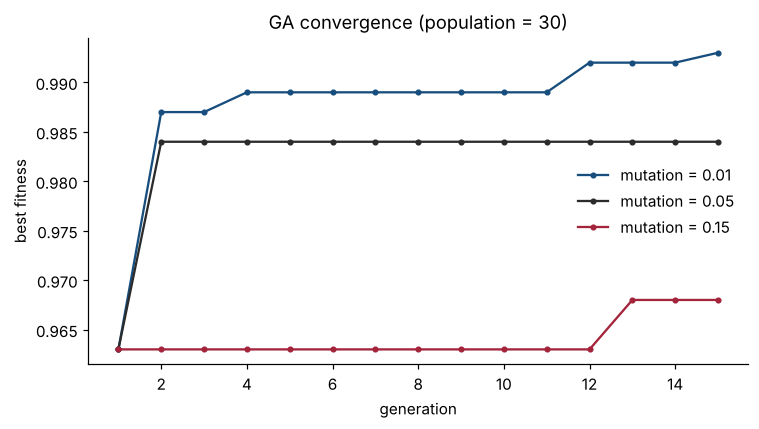

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for h, c in zip([h for h in hp if h["population"] == 30 and h["mutation"] != 0.02], [BLUE, "#2B2B2B", RED]):
    ax.plot(range(1, 16), h["history"], marker="o", ms=3, c=c, label=f"mutation = {h['mutation']}")
ax.set(xlabel="generation", ylabel="best fitness", title="GA convergence (population = 30)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "convergence.png", dpi=200)

Patient similarity network on the 10 final genes: Gaussian kernel similarity, k-NN graph (k = 5),
Louvain communities compared with ROP status. Exploratory only.

In [4]:
import networkx as nx
from sklearn.metrics import adjusted_rand_score, pairwise_distances
from sklearn.preprocessing import StandardScaler

import json
chosen = json.loads((RESULTS / "final_ga.json").read_text())["genes"]
Z = StandardScaler().fit_transform(expr[chosen])
d = pairwise_distances(Z)
sim = np.exp(-d ** 2 / (2 * np.median(d[d > 0]) ** 2))
np.fill_diagonal(sim, 0)

G = nx.Graph()
G.add_nodes_from(range(30))
for i in range(30):
    for j in np.argsort(-sim[i])[:5]:
        G.add_edge(i, int(j), weight=sim[i, j])

parts = nx.community.louvain_communities(G, weight="weight", seed=42)
label = np.zeros(30, dtype=int)
for c, nodes in enumerate(parts):
    label[list(nodes)] = c
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, {nx.number_connected_components(G)} component(s)")
print(f"{len(parts)} communities, ARI vs ROP status = {adjusted_rand_score(y, label):.3f}")

30 nodes, 102 edges, 1 component(s)
4 communities, ARI vs ROP status = 0.201


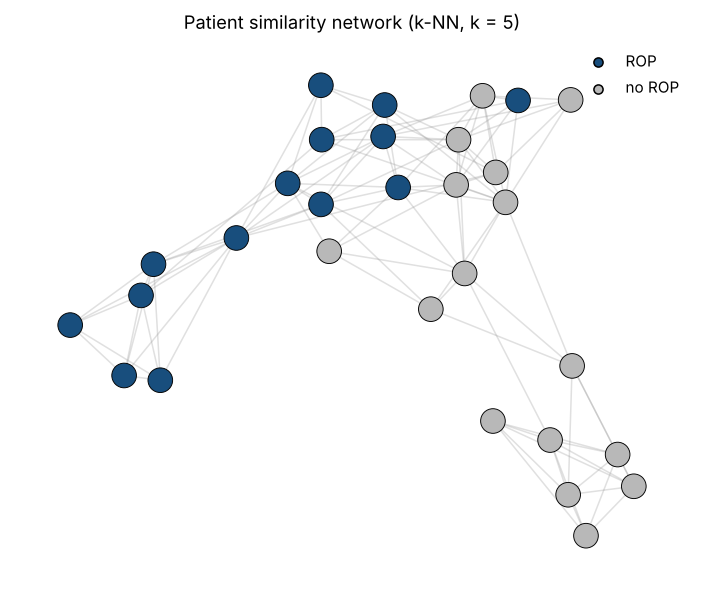

In [5]:
pos = nx.spring_layout(G, seed=42, k=0.6)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color="#999999", ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=[BLUE if v else GRAY for v in y], node_size=260,
                       edgecolors="black", linewidths=0.6, ax=ax)
ax.scatter([], [], c=BLUE, edgecolors="black", label="ROP")
ax.scatter([], [], c=GRAY, edgecolors="black", label="no ROP")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Patient similarity network (k-NN, k = 5)")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "patient_network.png", dpi=200)